
# Лабораторная работа №8: составление заголовков к изображениям

**Тема:** Image Captioning: от простого декодирования эмбеддингов до CNN+RNN и ViT+RNN.

**Цель:** реализовать базовые компоненты системы генерации описаний изображений, посчитать метрики BLEU и CIDEr, а затем сравнить две архитектуры энкодер-декодерного типа: `CNN + RNN` и `ViT + RNN`.

## Что нужно сдать

1. Заполненный ноутбук с решениями всех задач.
2. Краткий вывод: какая архитектура показала лучшие значения BLEU/CIDEr и почему.
3. Таблицу с результатами экспериментов.

## Минимальный набор библиотек

```python
numpy, pandas, torch, torchvision, matplotlib
```

Если GPU недоступен, используйте маленький датасет или демонстрационный режим из ноутбука.

## Обозначения

Пусть изображение $I$ кодируется энкодером в вектор признаков $z = f_\theta(I)$.
Декодер генерирует подпись токен за токеном:

$$
p(y_{1:T}\mid I)=\prod_{t=1}^{T} p(y_t\mid y_{<t}, z).
$$

Для RNN/LSTM-декодера:

$$
h_t = \operatorname{RNN}(E[y_{t-1}], h_{t-1}), \qquad
p(y_t\mid y_{<t}, z)=\operatorname{softmax}(W_o h_t+b_o).
$$

Обычно $z$ либо используется для инициализации скрытого состояния, либо подается как дополнительный вход на каждом шаге.



## Метрики

### BLEU

BLEU измеряет совпадение $n$-грамм между кандидатом $c$ и эталонными подписями $R$.

Модифицированная точность для $n$-грамм:

$$
p_n = \frac{\sum_{g\in G_n(c)} \min\left(\operatorname{count}_c(g),\max_{r\in R}\operatorname{count}_r(g)\right)}{\sum_{g\in G_n(c)}\operatorname{count}_c(g)}.
$$

Brevity penalty (штраф за краткость):

$$
BP = \begin{cases}
1, & |c| > r^*,\\
\exp(1-r^*/|c|), & |c| \le r^*,
\end{cases}
$$

где $r^*$ — длина эталона, ближайшая к длине кандидата.

Итоговый BLEU-N:

$$
BLEU_N = BP\cdot \exp\left(\sum_{n=1}^{N} w_n\log p_n\right), \qquad w_n=\frac{1}{N}.
$$

### CIDEr

CIDEr сравнивает TF-IDF-векторы $n$-грамм кандидата и эталонов.

TF-IDF-вес $n$-граммы $g$ в предложении $s$:

$$
v_g(s)=\frac{\operatorname{count}_s(g)}{\sum_{g'\in G_n(s)}\operatorname{count}_s(g')}\cdot
\log\left(\frac{|D|}{df(g)}\right),
$$

где $D$ — набор изображений/документов, а $df(g)$ — число документов, в которых встречается $g$.

Сходство для порядка $n$:

$$
CIDEr_n(c,R)=\frac{1}{|R|}\sum_{r\in R}\frac{v_n(c)\cdot v_n(r)}{\lVert v_n(c)\rVert_2\lVert v_n(r)\rVert_2}.
$$

Итог:

$$
CIDEr(c,R)=\frac{1}{N}\sum_{n=1}^{N} CIDEr_n(c,R).
$$

В классической версии CIDEr обычно используют $N=4$ и масштабирование на 10, но в этой лабораторной достаточно явно указать, используете ли вы масштабирование.


## Подготовка окружения

In [1]:
import copy
import math
import random
import re
import sys
from collections import Counter
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from PIL import Image

try:
    import torch
    import torch.nn as nn
    from torch.utils.data import Dataset, DataLoader
    from torchvision import transforms
    TORCH_AVAILABLE = True
except Exception as e:
    TORCH_AVAILABLE = False
    print("PyTorch недоступен:", e)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

if TORCH_AVAILABLE:
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
        torch.backends.cudnn.benchmark = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Python: {sys.executable}")
    print(f"PyTorch: {torch.__version__}")
    print(f"CUDA available: {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        print(f"CUDA runtime: {torch.version.cuda}")
        print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    device = None


Python: c:\Users\Rog G16\.conda\envs\FU\python.exe
PyTorch: 2.12.0+cu130
CUDA available: True
CUDA runtime: 13.0
GPU: NVIDIA GeForce RTX 5070 Ti Laptop GPU


## Демонстрационные данные

Generating train split:   0%|          | 0/833 [00:00<?, ? examples/s]

Dataset: reach-vb/pokemon-blip-captions
Examples: 833
Example caption: a drawing of a green pokemon with red eyes
train=583, val=125, test=125


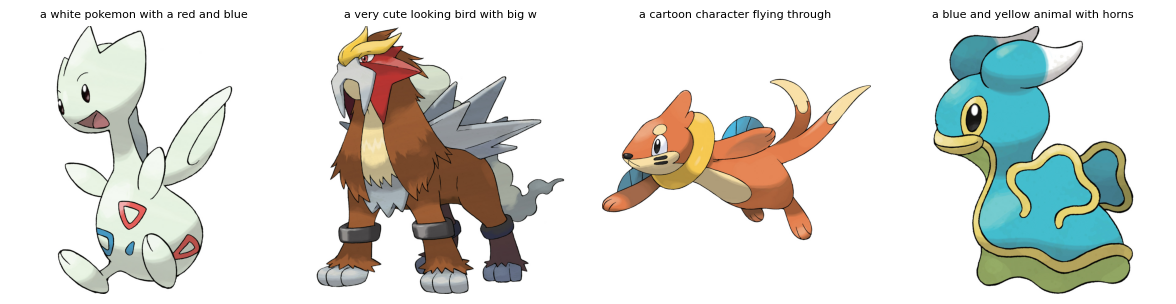

,image_id,candidate
0,img_0271,a purple elephant with a
1,img_0146,a bird with a long beak flying through
2,img_0469,a blue and white cartoon dog with a
3,img_0658,a cartoon character with a sword in
4,img_0405,a blue and purple dragon with a


In [2]:
# Для полноценного запуска беру небольшой открытый image-captioning датасет.
# В нем 833 пары: изображение + текстовая подпись.
DATASET_NAME = "reach-vb/pokemon-blip-captions"
MAX_EXAMPLES = None  # None = использовать весь датасет

raw_dataset = load_dataset(DATASET_NAME, split="train", download_mode="reuse_cache_if_exists")
if MAX_EXAMPLES is not None:
    raw_dataset = raw_dataset.select(range(min(MAX_EXAMPLES, len(raw_dataset))))

caption_records = []
for idx, item in enumerate(raw_dataset):
    caption = item["text"].strip()
    caption_records.append({
        "image_id": f"img_{idx:04d}",
        "row_id": idx,
        "caption": caption,
        "references": [caption],
    })

print(f"Dataset: {DATASET_NAME}")
print(f"Examples: {len(caption_records)}")
print("Example caption:", caption_records[0]["caption"])

indices = list(range(len(caption_records)))
random.Random(SEED).shuffle(indices)
train_end = int(0.70 * len(indices))
val_end = int(0.85 * len(indices))
train_indices = indices[:train_end]
val_indices = indices[train_end:val_end]
test_indices = indices[val_end:]

train_records = [caption_records[i] for i in train_indices]
val_records = [caption_records[i] for i in val_indices]
test_records = [caption_records[i] for i in test_indices]

print(f"train={len(train_records)}, val={len(val_records)}, test={len(test_records)}")

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, record in zip(axes, train_records[:4]):
    ax.imshow(raw_dataset[record["row_id"]]["image"].convert("RGB"))
    ax.set_title(record["caption"][:35], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

# Небольшой список для проверки BLEU/CIDEr до обучения моделей.
examples = []
for record in test_records[:5]:
    tokens = re.findall(r"[a-z0-9]+", record["caption"].lower())
    candidate = " ".join(tokens[:max(3, len(tokens) - 2)])
    examples.append({
        "image_id": record["image_id"],
        "candidate": candidate,
        "references": record["references"],
    })

pd.DataFrame([{k: v for k, v in item.items() if k != "references"} for item in examples])



## Задача 1. Токенизация, словарь и простейший декодер эмбеддингов

В этой задаче нужно реализовать подготовку текста и простейший бейзлайн: линейное отображение из эмбеддинга изображения в пространство токенов.

Пусть у нас есть готовый эмбеддинг изображения $z\in\mathbb{R}^d$. Простейший декодер без рекуррентности может выбрать первое слово как:

$$
\hat y_1 = \arg\max_j \operatorname{softmax}(Wz+b)_j.
$$

Затем можно повторить эту операцию для нескольких позиций, если использовать отдельную матрицу для каждой позиции:

$$
P\in\mathbb{R}^{T\times |V|}, \qquad P_t = \operatorname{softmax}(W_tz+b_t).
$$

**Что сделать:**

1. Реализуйте токенизацию.
2. Постройте словарь по эталонным подписям.
3. Создайте случайные эмбеддинги изображений.
4. Реализуйте декодирование `argmax` для фиксированной длины подписи.
5. Объясните, почему такой подход плохо моделирует язык.


In [3]:
def tokenize(text: str):
    """Простая токенизация для английских подписей."""
    return re.findall(r"[a-z0-9]+", text.lower())


SPECIAL_TOKENS = ["<pad>", "<bos>", "<eos>", "<unk>"]
MIN_FREQ = 1

counter = Counter()
for record in train_records:
    counter.update(tokenize(record["caption"]))

vocab = SPECIAL_TOKENS + sorted([token for token, count in counter.items() if count >= MIN_FREQ])
token_to_id = {token: idx for idx, token in enumerate(vocab)}
id_to_token = {idx: token for token, idx in token_to_id.items()}

PAD_ID = token_to_id["<pad>"]
BOS_ID = token_to_id["<bos>"]
EOS_ID = token_to_id["<eos>"]
UNK_ID = token_to_id["<unk>"]

print(f"Vocabulary size: {len(vocab)}")
print("First tokens:", vocab[:20])

rng = np.random.default_rng(SEED)
num_images = len(examples)
embed_dim = 32
max_caption_len = 8
image_embeddings = rng.normal(size=(num_images, embed_dim)).astype(np.float32)

W = rng.normal(scale=0.1, size=(max_caption_len, embed_dim, len(vocab))).astype(np.float32)
b = np.zeros((max_caption_len, len(vocab)), dtype=np.float32)


def decode_linear_embeddings(image_embeddings, W, b, id_to_token):
    decoded = []
    for z in image_embeddings:
        logits = np.einsum("tdv,d->tv", W, z) + b
        token_ids = logits.argmax(axis=1)
        tokens = [id_to_token[int(token_id)] for token_id in token_ids]
        tokens = [token for token in tokens if token not in {"<pad>", "<bos>", "<eos>"}]
        decoded.append(" ".join(tokens))
    return decoded


linear_predictions = decode_linear_embeddings(image_embeddings, W, b, id_to_token)
for item, prediction in zip(examples, linear_predictions):
    print(item["image_id"], "->", prediction)

print("Такой baseline почти не учитывает структуру языка: каждое место в подписи выбирается независимо.")


Vocabulary size: 316
First tokens: ['<pad>', '<bos>', '<eos>', '<unk>', 'a', 'accents', 'air', 'an', 'and', 'angry', 'animal', 'antennae', 'antlers', 'arms', 'around', 'arrow', 'at', 'back', 'background', 'backpack']
img_0271 -> toothbrush plant each group mouth top white paper
img_0146 -> hat very close glasses metal cat soccer long
img_0469 -> <unk> over pair bee grey look cap fish
img_0658 -> purple hat big gears wheel spread standing big
img_0405 -> tail picture vegetable smile flower middle outfit lizard
Такой baseline почти не учитывает структуру языка: каждое место в подписи выбирается независимо.



## Задача 2. Ручная реализация BLEU

Реализуйте BLEU-1...BLEU-4 без использования готовых библиотек.

**Что сделать:**

1. Напишите функцию получения $n$-грамм.
2. Реализуйте modified precision.
3. Реализуйте brevity penalty.
4. Реализуйте BLEU-N.
5. Посчитайте BLEU-1...BLEU-4 для каждого примера и среднее значение по датасету.

**Подсказка:** если $p_n=0$, можно использовать сглаживание, например прибавить `eps=1e-9`.


In [4]:
def ngrams(tokens, n):
    tokens = list(tokens)
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]


def _as_tokens(sentence_or_tokens):
    if isinstance(sentence_or_tokens, str):
        return tokenize(sentence_or_tokens)
    return list(sentence_or_tokens)


def modified_precision(candidate, references, n):
    candidate = _as_tokens(candidate)
    references = [_as_tokens(reference) for reference in references]
    candidate_counts = Counter(ngrams(candidate, n))
    if not candidate_counts:
        return 0.0

    max_reference_counts = Counter()
    for reference in references:
        reference_counts = Counter(ngrams(reference, n))
        for gram, count in reference_counts.items():
            max_reference_counts[gram] = max(max_reference_counts[gram], count)

    clipped = sum(min(count, max_reference_counts[gram]) for gram, count in candidate_counts.items())
    return clipped / sum(candidate_counts.values())


def brevity_penalty(candidate, references):
    candidate = _as_tokens(candidate)
    references = [_as_tokens(reference) for reference in references]
    candidate_len = len(candidate)
    if candidate_len == 0:
        return 0.0
    reference_lens = [len(reference) for reference in references]
    closest_reference_len = min(reference_lens, key=lambda ref_len: (abs(ref_len - candidate_len), ref_len))
    if candidate_len > closest_reference_len:
        return 1.0
    return math.exp(1 - closest_reference_len / candidate_len)


def bleu(candidate, references, max_n=4, eps=1e-9):
    precisions = [modified_precision(candidate, references, n) for n in range(1, max_n + 1)]
    log_precision = sum(math.log(max(p, eps)) for p in precisions) / max_n
    return brevity_penalty(candidate, references) * math.exp(log_precision)


bleu_rows = []
for item in examples:
    row = {"image_id": item["image_id"], "candidate": item["candidate"]}
    for n in range(1, 5):
        row[f"BLEU-{n}"] = bleu(item["candidate"], item["references"], max_n=n)
    bleu_rows.append(row)

bleu_df = pd.DataFrame(bleu_rows)
display(bleu_df)
display(bleu_df[[f"BLEU-{n}" for n in range(1, 5)]].mean().to_frame("mean").T)


,image_id,candidate,BLEU-1,BLEU-2,BLEU-3,BLEU-4
0,img_0271,a purple elephant with a,0.670320,0.670320,0.670320,0.670320
1,img_0146,a bird with a long beak flying through,0.778801,0.778801,0.778801,0.778801
2,img_0469,a blue and white cartoon dog with a,0.778801,0.778801,0.778801,0.778801
3,img_0658,a cartoon character with a sword in,0.751477,0.751477,0.751477,0.751477
4,img_0405,a blue and purple dragon with a,0.751477,0.751477,0.751477,0.751477


,BLEU-1,BLEU-2,BLEU-3,BLEU-4
mean,0.746175,0.746175,0.746175,0.746175



## Задача 3. Ручная реализация CIDEr

Реализуйте упрощенную версию CIDEr на TF-IDF-векторах $n$-грамм.

**Что сделать:**

1. Постройте document frequency для $n$-грамм по корпусу эталонных подписей.
2. Реализуйте TF-IDF-вектор для предложения.
3. Реализуйте cosine similarity.
4. Посчитайте CIDEr для каждого примера.
5. Сравните ранжирование примеров по BLEU-4 и CIDEr.


In [5]:
def build_document_frequency(dataset, max_n=4):
    df = Counter()
    for item in dataset:
        seen_for_image = set()
        for reference in item["references"]:
            tokens = tokenize(reference)
            for n in range(1, max_n + 1):
                seen_for_image.update((n, gram) for gram in ngrams(tokens, n))
        df.update(seen_for_image)
    return df, len(dataset)


def tfidf_vector(tokens, n, df, num_docs):
    grams = ngrams(tokens, n)
    counts = Counter(grams)
    total = sum(counts.values())
    if total == 0:
        return {}

    vector = {}
    for gram, count in counts.items():
        tf = count / total
        idf = math.log((num_docs + 1) / (df.get((n, gram), 0) + 1))
        vector[gram] = tf * idf
    return vector


def cosine_dict(a, b):
    if not a or not b:
        return 0.0
    common = set(a) & set(b)
    numerator = sum(a[key] * b[key] for key in common)
    norm_a = math.sqrt(sum(value * value for value in a.values()))
    norm_b = math.sqrt(sum(value * value for value in b.values()))
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return numerator / (norm_a * norm_b)


def cider(candidate, references, df, num_docs, max_n=4, scale=10.0):
    candidate_tokens = _as_tokens(candidate)
    reference_tokens = [_as_tokens(reference) for reference in references]
    order_scores = []
    for n in range(1, max_n + 1):
        candidate_vector = tfidf_vector(candidate_tokens, n, df, num_docs)
        reference_scores = []
        for reference in reference_tokens:
            reference_vector = tfidf_vector(reference, n, df, num_docs)
            reference_scores.append(cosine_dict(candidate_vector, reference_vector))
        order_scores.append(sum(reference_scores) / max(len(reference_scores), 1))
    return scale * sum(order_scores) / max_n


df, num_docs = build_document_frequency(
    [{"references": record["references"]} for record in train_records + val_records + test_records],
    max_n=4,
)

cider_rows = []
for item in examples:
    cider_rows.append({
        "image_id": item["image_id"],
        "candidate": item["candidate"],
        "BLEU-4": bleu(item["candidate"], item["references"], max_n=4),
        "CIDEr": cider(item["candidate"], item["references"], df, num_docs),
    })

cider_df = pd.DataFrame(cider_rows).sort_values("CIDEr", ascending=False)
display(cider_df)


,image_id,candidate,BLEU-4,CIDEr
1,img_0146,a bird with a long beak flying through,0.778801,9.151141
2,img_0469,a blue and white cartoon dog with a,0.778801,8.669681
4,img_0405,a blue and purple dragon with a,0.751477,8.027099
0,img_0271,a purple elephant with a,0.670320,7.477786
3,img_0658,a cartoon character with a sword in,0.751477,7.372563


#Основная часть


## Задача 4. Архитектура CNN + RNN

Реализуйте модель `CNNEncoder + RNNDecoder`.

Типичный вариант:

$$
z = \operatorname{CNN}(I), \qquad h_0 = W_h z.
$$

Декодер получает на вход токены с teacher forcing:

$$
\mathcal{L} = -\sum_{t=1}^{T}\log p(y_t^*\mid y_{<t}^*, I).
$$

**Что сделать:**

1. Реализуйте `CNNEncoder`.
2. Реализуйте `RNNDecoder` на LSTM или GRU.
3. Реализуйте `CaptioningModel`.
4. Напишите training loop на 1–2 эпохи или на одном батче для smoke test.
5. Реализуйте greedy decoding.

**Подсказка:** можно использовать маленькую CNN с нуля, чтобы ноутбук работал без скачивания весов.


In [6]:
if TORCH_AVAILABLE:
    IMAGE_SIZE = 128
    MAX_LEN = 24
    BATCH_SIZE = 64 if device.type == "cuda" else 16
    CAPTION_EPOCHS = 20 if device.type == "cuda" else 3
    USE_AMP = device.type == "cuda"
    CHECKPOINT_DIR = Path("checkpoints") / "lab8_captioning"
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

    train_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])
    eval_transform = transforms.Compose([
        transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
    ])

    def encode_caption(text, max_len=MAX_LEN):
        ids = [BOS_ID] + [token_to_id.get(token, UNK_ID) for token in tokenize(text)] + [EOS_ID]
        ids = ids[:max_len]
        ids += [PAD_ID] * (max_len - len(ids))
        return ids

    def ids_to_caption(ids):
        tokens = []
        for token_id in ids:
            token_id = int(token_id)
            if token_id == EOS_ID:
                break
            if token_id in {PAD_ID, BOS_ID}:
                continue
            tokens.append(id_to_token.get(token_id, "<unk>"))
        return " ".join(tokens)

    class ImageCaptionDataset(Dataset):
        def __init__(self, records, hf_dataset, transform):
            self.records = records
            self.hf_dataset = hf_dataset
            self.transform = transform

        def __len__(self):
            return len(self.records)

        def __getitem__(self, index):
            record = self.records[index]
            image = self.hf_dataset[record["row_id"]]["image"].convert("RGB")
            image = self.transform(image)
            caption = torch.tensor(encode_caption(record["caption"]), dtype=torch.long)
            return image, caption, record["image_id"]

    train_loader = DataLoader(
        ImageCaptionDataset(train_records, raw_dataset, train_transform),
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=device.type == "cuda",
    )
    val_loader = DataLoader(
        ImageCaptionDataset(val_records, raw_dataset, eval_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=device.type == "cuda",
    )
    test_loader = DataLoader(
        ImageCaptionDataset(test_records, raw_dataset, eval_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=device.type == "cuda",
    )

    class CNNEncoder(nn.Module):
        def __init__(self, feature_dim=256):
            super().__init__()
            self.features = nn.Sequential(
                nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(32),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(64),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(128),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
                nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(256),
                nn.ReLU(inplace=True),
                nn.AdaptiveAvgPool2d((1, 1)),
            )
            self.proj = nn.Linear(256, feature_dim)

        def forward(self, images):
            return self.proj(self.features(images).flatten(1))

    class RNNDecoder(nn.Module):
        def __init__(self, vocab_size, token_embed_dim=128, hidden_dim=256, image_dim=256):
            super().__init__()
            self.embedding = nn.Embedding(vocab_size, token_embed_dim, padding_idx=PAD_ID)
            self.init_h = nn.Linear(image_dim, hidden_dim)
            self.gru = nn.GRU(token_embed_dim, hidden_dim, batch_first=True)
            self.output = nn.Linear(hidden_dim, vocab_size)

        def forward(self, image_features, input_tokens):
            embeddings = self.embedding(input_tokens)
            h0 = torch.tanh(self.init_h(image_features)).unsqueeze(0)
            outputs, _ = self.gru(embeddings, h0)
            return self.output(outputs)

        @torch.no_grad()
        def greedy_decode(self, image_features, max_len=MAX_LEN):
            batch_size = image_features.size(0)
            hidden = torch.tanh(self.init_h(image_features)).unsqueeze(0)
            current = torch.full((batch_size, 1), BOS_ID, dtype=torch.long, device=image_features.device)
            generated = []
            for _ in range(max_len - 1):
                embeddings = self.embedding(current[:, -1:])
                output, hidden = self.gru(embeddings, hidden)
                next_token = self.output(output[:, -1]).argmax(dim=-1)
                generated.append(next_token)
                current = torch.cat([current, next_token.unsqueeze(1)], dim=1)
            return torch.stack(generated, dim=1)

    class CaptioningModel(nn.Module):
        def __init__(self, encoder, decoder):
            super().__init__()
            self.encoder = encoder
            self.decoder = decoder

        def forward(self, images, captions):
            image_features = self.encoder(images)
            return self.decoder(image_features, captions[:, :-1])

        @torch.no_grad()
        def greedy_decode(self, images, max_len=MAX_LEN):
            return self.decoder.greedy_decode(self.encoder(images), max_len=max_len)

    def count_parameters(model):
        return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

    def token_accuracy(logits, targets):
        mask = targets != PAD_ID
        if mask.sum().item() == 0:
            return 0.0
        predictions = logits.argmax(dim=-1)
        return ((predictions == targets) & mask).sum().item() / mask.sum().item()

    def run_caption_epoch(model, loader, criterion, optimizer=None, scaler=None):
        is_train = optimizer is not None
        model.train(is_train)
        total_loss = 0.0
        total_acc = 0.0
        total_tokens = 0
        started = perf_counter()

        for images, captions, _ in loader:
            images = images.to(device, non_blocking=True)
            captions = captions.to(device, non_blocking=True)
            targets = captions[:, 1:]

            if is_train:
                optimizer.zero_grad(set_to_none=True)

            with torch.set_grad_enabled(is_train):
                with torch.amp.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                    logits = model(images, captions)
                    loss = criterion(logits.reshape(-1, logits.size(-1)), targets.reshape(-1))

                if is_train:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()

            non_pad = (targets != PAD_ID).sum().item()
            total_loss += loss.item() * non_pad
            total_acc += token_accuracy(logits.detach(), targets) * non_pad
            total_tokens += non_pad

        return {
            "loss": total_loss / max(total_tokens, 1),
            "token_acc": total_acc / max(total_tokens, 1),
            "seconds": perf_counter() - started,
        }

    def train_caption_model(model, model_name, epochs=CAPTION_EPOCHS, lr=1e-3, weight_decay=1e-4):
        model = model.to(device)
        criterion = nn.CrossEntropyLoss(ignore_index=PAD_ID)
        optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
        scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
        checkpoint_path = CHECKPOINT_DIR / f"{model_name.lower().replace('+', '_').replace(' ', '_')}_best.pt"

        best_loss = float("inf")
        best_state = None
        history = []
        for epoch in range(1, epochs + 1):
            train_metrics = run_caption_epoch(model, train_loader, criterion, optimizer, scaler)
            val_metrics = run_caption_epoch(model, val_loader, criterion)
            scheduler.step()
            row = {
                "model": model_name,
                "epoch": epoch,
                "train_loss": train_metrics["loss"],
                "train_token_acc": train_metrics["token_acc"],
                "val_loss": val_metrics["loss"],
                "val_token_acc": val_metrics["token_acc"],
                "seconds": train_metrics["seconds"],
            }
            history.append(row)
            if val_metrics["loss"] < best_loss:
                best_loss = val_metrics["loss"]
                best_state = copy.deepcopy(model.state_dict())
                torch.save({"epoch": epoch, "model_state": best_state, "val_loss": best_loss}, checkpoint_path)
            print(
                f"{model_name} epoch {epoch:02d}/{epochs}: "
                f"train_loss={row['train_loss']:.3f}, val_loss={row['val_loss']:.3f}, "
                f"val_token_acc={row['val_token_acc']:.3f}, time={row['seconds']:.1f}s"
            )

        if best_state is not None:
            model.load_state_dict(best_state)
        return history, checkpoint_path

    cnn_caption_model = CaptioningModel(
        CNNEncoder(feature_dim=256),
        RNNDecoder(vocab_size=len(vocab), token_embed_dim=128, hidden_dim=256, image_dim=256),
    )
    print("CNN+RNN parameters:", count_parameters(cnn_caption_model))

    RUN_TRAINING = True
    if RUN_TRAINING:
        cnn_history, cnn_checkpoint = train_caption_model(cnn_caption_model, "CNN+RNN", epochs=CAPTION_EPOCHS, lr=1e-3)
    else:
        cnn_history, cnn_checkpoint = [], None
else:
    print("PyTorch недоступен: CNN+RNN не запускается.")


CNN+RNN parameters: 938588
CNN+RNN epoch 01/20: train_loss=4.936, val_loss=3.604, val_token_acc=0.204, time=15.4s
CNN+RNN epoch 02/20: train_loss=3.285, val_loss=2.873, val_token_acc=0.436, time=11.6s
CNN+RNN epoch 03/20: train_loss=2.769, val_loss=2.562, val_token_acc=0.487, time=13.8s
CNN+RNN epoch 04/20: train_loss=2.448, val_loss=2.335, val_token_acc=0.521, time=13.7s
CNN+RNN epoch 05/20: train_loss=2.199, val_loss=2.168, val_token_acc=0.551, time=13.2s
CNN+RNN epoch 06/20: train_loss=2.017, val_loss=2.047, val_token_acc=0.575, time=11.1s
CNN+RNN epoch 07/20: train_loss=1.889, val_loss=1.966, val_token_acc=0.580, time=12.2s
CNN+RNN epoch 08/20: train_loss=1.794, val_loss=1.909, val_token_acc=0.583, time=11.1s
CNN+RNN epoch 09/20: train_loss=1.721, val_loss=1.863, val_token_acc=0.593, time=12.7s
CNN+RNN epoch 10/20: train_loss=1.665, val_loss=1.834, val_token_acc=0.596, time=12.4s
CNN+RNN epoch 11/20: train_loss=1.621, val_loss=1.810, val_token_acc=0.605, time=14.2s
CNN+RNN epoch 12


## Задача 5. Архитектура ViT + RNN

Теперь замените CNN-энкодер на ViT-подобный энкодер. В полном эксперименте можно использовать предобученный `vit_b_16`, но для лабораторной достаточно реализовать компактный ViT-like encoder.

Изображение разбивается на патчи. Для каждого патча строится эмбеддинг:

$$
x_i = W_p \operatorname{patch}_i + e_i.
$$

После Transformer Encoder берется CLS-токен или среднее по патчам:

$$
z = \operatorname{TransformerEncoder}(x)_{CLS}.
$$

**Что сделать:**

1. Реализуйте patch embedding.
2. Добавьте positional embeddings.
3. Реализуйте ViT-like encoder через `nn.TransformerEncoder`.
4. Подключите тот же RNN-декодер.
5. Сравните число параметров и smoke-test loss с CNN+RNN.


In [7]:
if TORCH_AVAILABLE:
    class MiniViTEncoder(nn.Module):
        def __init__(self, image_size=IMAGE_SIZE, patch_size=16, embed_dim=256, depth=4,
                     num_heads=4, mlp_dim=512, feature_dim=256, dropout=0.1):
            super().__init__()
            assert image_size % patch_size == 0
            self.num_patches = (image_size // patch_size) ** 2
            self.patch_embed = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)
            self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
            self.pos_embed = nn.Parameter(torch.zeros(1, self.num_patches + 1, embed_dim))
            encoder_layer = nn.TransformerEncoderLayer(
                d_model=embed_dim,
                nhead=num_heads,
                dim_feedforward=mlp_dim,
                dropout=dropout,
                activation="gelu",
                batch_first=True,
                norm_first=True,
            )
            self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=depth, enable_nested_tensor=False)
            self.norm = nn.LayerNorm(embed_dim)
            self.proj = nn.Linear(embed_dim, feature_dim)
            nn.init.trunc_normal_(self.cls_token, std=0.02)
            nn.init.trunc_normal_(self.pos_embed, std=0.02)

        def forward(self, images):
            x = self.patch_embed(images).flatten(2).transpose(1, 2)
            cls = self.cls_token.expand(x.size(0), -1, -1)
            x = torch.cat([cls, x], dim=1)
            x = x + self.pos_embed[:, :x.size(1)]
            x = self.encoder(x)
            return self.proj(self.norm(x[:, 0]))

    vit_caption_model = CaptioningModel(
        MiniViTEncoder(feature_dim=256),
        RNNDecoder(vocab_size=len(vocab), token_embed_dim=128, hidden_dim=256, image_dim=256),
    )
    print("ViT+RNN parameters:", count_parameters(vit_caption_model))
    print("CNN+RNN parameters:", count_parameters(cnn_caption_model))

    if RUN_TRAINING:
        vit_history, vit_checkpoint = train_caption_model(vit_caption_model, "ViT+RNN", epochs=CAPTION_EPOCHS, lr=5e-4)
    else:
        vit_history, vit_checkpoint = [], None
else:
    print("PyTorch недоступен: ViT+RNN не запускается.")


ViT+RNN parameters: 2872380
CNN+RNN parameters: 938588
ViT+RNN epoch 01/20: train_loss=5.250, val_loss=4.512, val_token_acc=0.220, time=10.8s
ViT+RNN epoch 02/20: train_loss=4.105, val_loss=3.518, val_token_acc=0.192, time=12.4s
ViT+RNN epoch 03/20: train_loss=3.386, val_loss=3.152, val_token_acc=0.397, time=13.0s
ViT+RNN epoch 04/20: train_loss=3.074, val_loss=2.890, val_token_acc=0.442, time=10.8s
ViT+RNN epoch 05/20: train_loss=2.838, val_loss=2.706, val_token_acc=0.462, time=11.8s
ViT+RNN epoch 06/20: train_loss=2.648, val_loss=2.562, val_token_acc=0.490, time=12.8s
ViT+RNN epoch 07/20: train_loss=2.494, val_loss=2.444, val_token_acc=0.506, time=13.5s
ViT+RNN epoch 08/20: train_loss=2.363, val_loss=2.350, val_token_acc=0.532, time=12.8s
ViT+RNN epoch 09/20: train_loss=2.257, val_loss=2.276, val_token_acc=0.543, time=12.6s
ViT+RNN epoch 10/20: train_loss=2.176, val_loss=2.216, val_token_acc=0.547, time=13.4s
ViT+RNN epoch 11/20: train_loss=2.112, val_loss=2.169, val_token_acc=0.556,


## Задача 6. Экспериментальное сравнение и анализ ошибок

В финальной задаче нужно оформить сравнение подходов.

**Что сделать:**

1. Сгенерируйте подписи для валидационных изображений с помощью CNN+RNN и ViT+RNN.
2. Посчитайте BLEU-1...BLEU-4 и CIDEr.
3. Составьте таблицу результатов.
4. Выведите несколько примеров: изображение, reference, prediction.
5. Напишите вывод: какие ошибки чаще встречаются?

Пример структуры таблицы:

| model | BLEU-1 | BLEU-2 | BLEU-3 | BLEU-4 | CIDEr |
|---|---:|---:|---:|---:|---:|
| CNN+RNN | ... | ... | ... | ... | ... |
| ViT+RNN | ... | ... | ... | ... | ... |

**Критерии анализа:**

- ошибки объектов;
- ошибки атрибутов;
- ошибки действий;
- повторения токенов;
- слишком короткие/слишком общие подписи.


,model,BLEU-1,BLEU-2,BLEU-3,BLEU-4,CIDEr
0,CNN+RNN,0.436431,0.332686,0.240609,0.190743,0.747033
1,ViT+RNN,0.401164,0.298005,0.205078,0.154223,0.566103


,model,epoch,train_loss,train_token_acc,val_loss,val_token_acc,seconds
0,CNN+RNN,1,4.936108,0.215127,3.604442,0.203846,15.422004
1,CNN+RNN,2,3.285035,0.325925,2.873031,0.436154,11.634336
2,CNN+RNN,3,2.768547,0.446840,2.561643,0.486923,13.769423
3,CNN+RNN,4,2.447793,0.490794,2.335064,0.520769,13.679507
4,CNN+RNN,5,2.198815,0.531597,2.168459,0.550769,13.180928
5,CNN+RNN,6,2.017075,0.556809,2.047018,0.574615,11.145804
6,CNN+RNN,7,1.889042,0.562780,1.966233,0.580000,12.159287
7,CNN+RNN,8,1.793687,0.585669,1.909421,0.583077,11.125565
8,CNN+RNN,9,1.720681,0.594792,1.863161,0.593077,12.714511
9,CNN+RNN,10,1.664704,0.605739,1.833811,0.596154,12.433056


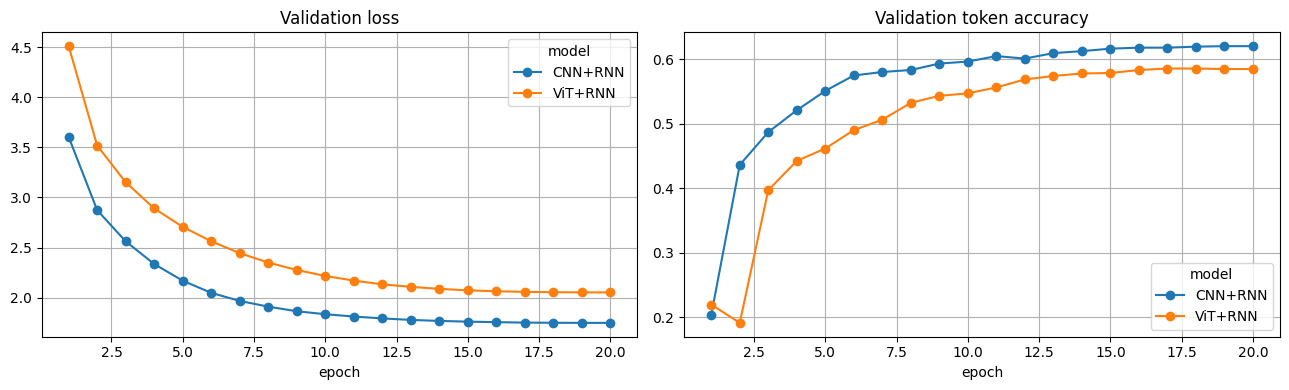

Примеры подписей CNN+RNN:


,reference,prediction,BLEU-4,CIDEr
0,a purple elephant with a yellow tusk,a drawing of a cartoon character with a big smile,0.000014,0.066281
1,a bird with a long beak flying through the air,a drawing of a cartoon character with a big smile,0.000014,0.065328
2,a blue and white cartoon dog with a hat on,a drawing of a cartoon character with a big smile,0.000015,0.147508
3,a cartoon character with a sword in his hand,a drawing of a cartoon character with a big smile,0.392815,1.205864
4,a blue and purple dragon with a black mouth,a drawing of a cartoon character with a big smile,0.000014,0.070999
5,a cartoon character is holding a baseball bat,a drawing of a cartoon character with a big smile,0.001826,0.358722
6,a drawing of a flower with a bird on it,a drawing of a cartoon character with a big smile,0.312394,0.412704
7,a picture of a pokemon with a leaf on its back,a drawing of a cartoon character with a big smile,0.000017,0.125835


Примеры подписей ViT+RNN:


,reference,prediction,BLEU-4,CIDEr
0,a purple elephant with a yellow tusk,a drawing of a cartoon character with a pink o...,0.000012,0.046820
1,a bird with a long beak flying through the air,a drawing of a cartoon character with a pink o...,0.000012,0.046494
2,a blue and white cartoon dog with a hat on,a drawing of a cartoon character with a pink o...,0.000014,0.286338
3,a cartoon character with a sword in his hand,a drawing of a cartoon character with a pink o...,0.317023,0.765274
4,a blue and purple dragon with a black mouth,a drawing of a cartoon character with a pink o...,0.000012,0.051716
5,a cartoon character is holding a baseball bat,a drawing of a cartoon character with a pink o...,0.001569,0.268942
6,a drawing of a flower with a bird on it,a drawing of a cartoon character with a pink o...,0.262025,0.495321
7,a picture of a pokemon with a leaf on its back,a drawing of a cartoon character with a pink o...,0.000020,0.747048


In [8]:
# Генерация подписей и финальная оценка
def generate_prediction_dict(model, loader):
    model.eval()
    predictions = {}
    with torch.no_grad():
        for images, _, image_ids in loader:
            images = images.to(device, non_blocking=True)
            generated = model.greedy_decode(images, max_len=MAX_LEN).cpu()
            for image_id, token_ids in zip(image_ids, generated):
                predictions[image_id] = ids_to_caption(token_ids.tolist())
    return predictions


def evaluate_predictions(predictions, records):
    rows = []
    for record in records:
        prediction = predictions.get(record["image_id"], "")
        rows.append({
            "image_id": record["image_id"],
            "reference": record["caption"],
            "prediction": prediction,
            "BLEU-1": bleu(prediction, record["references"], max_n=1),
            "BLEU-2": bleu(prediction, record["references"], max_n=2),
            "BLEU-3": bleu(prediction, record["references"], max_n=3),
            "BLEU-4": bleu(prediction, record["references"], max_n=4),
            "CIDEr": cider(prediction, record["references"], df, num_docs),
        })
    return pd.DataFrame(rows)


if TORCH_AVAILABLE and RUN_TRAINING:
    cnn_predictions = generate_prediction_dict(cnn_caption_model, test_loader)
    vit_predictions = generate_prediction_dict(vit_caption_model, test_loader)

    cnn_eval = evaluate_predictions(cnn_predictions, test_records)
    vit_eval = evaluate_predictions(vit_predictions, test_records)

    summary_rows = []
    for model_name, frame in [("CNN+RNN", cnn_eval), ("ViT+RNN", vit_eval)]:
        means = frame[["BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4", "CIDEr"]].mean().to_dict()
        means["model"] = model_name
        summary_rows.append(means)

    results_table = pd.DataFrame(summary_rows)[["model", "BLEU-1", "BLEU-2", "BLEU-3", "BLEU-4", "CIDEr"]]
    display(results_table)

    history_df = pd.DataFrame(cnn_history + vit_history)
    display(history_df)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    history_df.pivot(index="epoch", columns="model", values="val_loss").plot(marker="o", ax=axes[0])
    axes[0].set_title("Validation loss")
    axes[0].grid(True)
    history_df.pivot(index="epoch", columns="model", values="val_token_acc").plot(marker="o", ax=axes[1])
    axes[1].set_title("Validation token accuracy")
    axes[1].grid(True)
    plt.tight_layout()
    plt.show()

    print("Примеры подписей CNN+RNN:")
    display(cnn_eval[["reference", "prediction", "BLEU-4", "CIDEr"]].head(8))
    print("Примеры подписей ViT+RNN:")
    display(vit_eval[["reference", "prediction", "BLEU-4", "CIDEr"]].head(8))
else:
    print("Обучение не запускалось, поэтому финальная таблица не построена.")


## Контрольные вопросы

1. Почему BLEU может быть низким для хорошей по смыслу подписи?  
   BLEU сравнивает точные n-граммы. Если модель описала картинку правильно, но другими словами, BLEU может быть низким.

2. Зачем CIDEr использует IDF-веса?  
   IDF уменьшает вклад частых слов и усиливает редкие, более информативные слова.

3. В чем преимущество предобученного энкодера изображения?  
   Предобученный энкодер уже умеет выделять визуальные признаки, поэтому captioning-модель быстрее обучается и обычно дает более качественные подписи.

4. Почему ViT обычно требует больше данных или предобучения, чем небольшая CNN?  
   CNN изначально хорошо работает с локальными признаками изображения. ViT более универсален, но без предобучения ему нужно больше данных, чтобы выучить такие закономерности.

5. Чем greedy decoding отличается от beam search?  
   Greedy decoding на каждом шаге выбирает один самый вероятный токен. Beam search хранит несколько вариантов подписи и обычно дает лучшее качество, но работает медленнее.
